# A Semi-Multiplicative MMM with Terms

In [Rebuilding the Reference MMMs](experimental_mmm_api.ipynb), we used the experimental API to write the same additive models as the stable `MMM` class. Here we change the model itself: media adds demand, while price and distribution scale the demand that can become sales. This is the semi-multiplicative structure discussed in [issue #3088](https://github.com/pymc-labs/pymc-marketing/issues/3088).

We generate weekly data from a known model, write its equation with terms, fit it and recover its parameters and media effects. We then forecast twelve weeks, compare two price scenarios and jointly optimize media spend and price. The purpose is the model definition, not a new model class: `GAM`, `Data`, `Equation` and the existing terms are enough.

> **Warning:** The experimental API is under active development. This notebook uses its own namespace and does not change the stable `MMM` class.

## The Model

Let $f_c$ be normalized geometric adstock followed by logistic saturation. The additive demand block and the market multiplier are

$$
A_t = b + \sum_c \beta_c f_c(x_{c,t}), \qquad
M_t = \left(\frac{p_t}{p_{\mathrm{ref}}}\right)^{\gamma_p}
      \left(\frac{d_t}{d_{\mathrm{ref}}}\right)^{\gamma_d}.
$$

Weekly sales have a semi-multiplicative mean but additive observation noise:

$$
y_t \sim \operatorname{Normal}(A_t M_t, \sigma).
$$

At reference price and distribution, $M_t=1$ and the mean reduces to the additive model. Price and distribution are strictly positive. A positive baseline and positive media amplitudes make $A_t>0$ by construction; we do not apply a hidden transform to a signed additive predictor. Choosing this structure does not force a LogNormal likelihood.

The price exponent is a conditional elasticity of expected sales, holding spend and distribution fixed. The distribution exponent has the analogous interpretation. These are assumptions of the simulated model, not a claim that fitting observational data would identify causal effects.

## Prepare Notebook

In [1]:
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pymc.dims as pmd
import pytensor.xtensor as ptx
import xarray as xr
from IPython.display import display
from pymc_extras.printing import model_table
from pymc_extras.prior import Prior

from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation
from pymc_marketing.mmm.experimental import GAM, Data, Equation, optimize
from pymc_marketing.terms import Named, Parameter, Transform

warnings.filterwarnings("ignore", category=FutureWarning)
az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [10, 4]
plt.rcParams["figure.dpi"] = 70
rng = np.random.default_rng(sum(map(ord, "semi-multiplicative")))

## Data Generating Process

We simulate two channels, price and distribution independently so that their effects can be separated in this example. Each channel sometimes turns off. There are 208 training weeks followed by twelve weeks reserved for a forecast check. The process has no spend before the first simulated week.

We declare the units once: channel spend is divided by a fixed per-channel amount, sales are measured in thousands, and the price and distribution references are 10 and 0.8. These constants are reused for training and forecasting; none is recomputed from future data. Distribution stays between zero and one, and its reference is a neutral condition rather than an upper bound.

In [2]:
n_train, n_forecast, l_max = 208, 12, 8
n_weeks = n_train + n_forecast
dates = pd.date_range("2020-01-06", periods=n_weeks, freq="W-MON")
channels = ["x1", "x2"]
channel_scale = xr.DataArray(
    [100.0, 80.0], dims="channel", coords={"channel": channels}
)
target_scale = 1_000.0
price_reference, distribution_reference = 10.0, 0.8

true_baseline, true_sigma = 1_000.0, 60.0
true_alpha = np.array([0.4, 0.2])
true_lam = np.array([3.0, 4.0])
true_beta = np.array([700.0, 400.0])
true_price_elasticity, true_distribution_elasticity = -1.2, 0.8

spend_scaled = rng.uniform(0.0, 1.0, size=(n_weeks, len(channels)))
spend_scaled *= rng.random(spend_scaled.shape) > 0.2
price = price_reference * rng.uniform(0.8, 1.2, size=n_weeks)
distribution = rng.uniform(0.55, 0.98, size=n_weeks)

# NumPy computation, independent of the graph we fit below.
adstocked = np.column_stack(
    [
        np.convolve(
            spend_scaled[:, c],
            alpha ** np.arange(l_max) / (alpha ** np.arange(l_max)).sum(),
        )[:n_weeks]
        for c, alpha in enumerate(true_alpha)
    ]
)
true_media_at_reference = true_beta * np.tanh(true_lam * adstocked / 2)
true_additive = true_baseline + true_media_at_reference.sum(axis=1)
true_multiplier = (price / price_reference) ** true_price_elasticity * (
    distribution / distribution_reference
) ** true_distribution_elasticity
true_response = true_additive * true_multiplier
true_media_contribution = true_media_at_reference * true_multiplier[:, None]

original = xr.Dataset(
    {
        "spend": (("date", "channel"), spend_scaled * channel_scale.values),
        "price": ("date", price),
        "distribution": ("date", distribution),
        "sales": ("date", true_response + rng.normal(0.0, true_sigma, n_weeks)),
    },
    coords={"date": dates, "channel": channels},
)
scaled = original.assign(
    spend=original["spend"] / channel_scale,
    sales=original["sales"] / target_scale,
)
train = scaled.isel(date=slice(0, n_train))
future = scaled.isel(date=slice(n_train, None)).drop_vars("sales")
print(f"Training weeks: {train.sizes['date']}; forecast weeks: {future.sizes['date']}")
print(
    f"Price reference: {price_reference}; distribution reference: {distribution_reference}"
)

Training weeks: 208; forecast weeks: 12
Price reference: 10.0; distribution reference: 0.8


## Model Specification

The media pipeline is the same as in the reference notebook. Its output is named `media_at_reference`: it is an additive sales effect **at neutral market conditions**, not yet the realized effect under the current price and distribution.

We express each power factor in log space, $\gamma\log(x/x_{\mathrm{ref}})$, and exponentiate their sum. This is exactly $(1+z)^\gamma$ for a proportional change $z=x/x_{\mathrm{ref}}-1$. `Transform` applies an ordinary named PyTensor operation to a lazy term; `Parameter` declares its coefficient. The illustrative priors below are on the declared model scale, so media amplitudes are in thousands of sales and elasticities are dimensionless.

The baseline is a `Prior` directly, with `Named` used only to retain a readable `baseline` output. It creates the free variable `baseline_param` and records its value as `baseline`; it is not an `Intercept` or `Parameter` term.

In [3]:
spend_data = Data("spend")
price_data = Data("price")
distribution_data = Data("distribution")

media_at_reference = (
    spend_data
    >> GeometricAdstock(l_max=l_max, priors={"alpha": Prior("Beta", alpha=2, beta=5)})
    >> LogisticSaturation(
        priors={
            "beta": Prior("HalfNormal", sigma=0.8),
            "lam": Prior("Gamma", alpha=3, beta=1),
        }
    )
).named("media_at_reference")

baseline = Named("baseline", Prior("Gamma", mu=1.0, sigma=0.5))
additive = (baseline + media_at_reference.sum("channel")).named("additive_block")

price_elasticity = Parameter("price_elasticity", prior=Prior("Normal", mu=0, sigma=1))
distribution_elasticity = Parameter(
    "distribution_elasticity", prior=Prior("Normal", mu=0, sigma=1)
)
price_log_factor = (
    price_elasticity
    * Transform(price_data * (1.0 / price_reference), func=ptx.math.log)
).named("price_log_factor")
distribution_log_factor = (
    distribution_elasticity
    * Transform(distribution_data * (1.0 / distribution_reference), func=ptx.math.log)
).named("distribution_log_factor")
market_multiplier = Transform(
    price_log_factor + distribution_log_factor, func=ptx.math.exp
).named("market_multiplier")

sales_response = (additive * market_multiplier).named("sales_response")

sales = Equation(
    name="y",
    observed="sales",
    mu=sales_response,
    likelihood=Prior("Normal", sigma=Prior("HalfNormal", sigma=0.2)),
)
gam = GAM(sales)
gam.build_model(train)
model_table(gam.model)

                  Variable  Expression                                                      Dimensions             
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
    _experimental_data_0 =  Data                                                            date[208] × channel[2] 
    _experimental_data_1 =  Data                                                            date[208]              
    _experimental_data_2 =  Data                                                            date[208]              
                                                                                                                   
          baseline_param ~  Gamma(<constant>, <constant>)                                                          
           adstock_alpha ~  Beta(2, 5)                                                      channel[2]             
          saturation_lam ~  Gamma(3, <constant>)                                            channel[2]             
         saturation_beta ~  HalfNormal(0, 0.8)                                              channel[2]             
        price_elasticity ~  Normal(0, 1)                                                                           
 distribution_elasticity ~  Normal(0, 1)                                                                           
                 y_sigma ~  HalfNormal(0, 0.2)                                                                     
                                                                                            Parameter count = 10   
                                                                                                                   
                baseline =  f(baseline_param)                                                                      
      media_at_reference =  f(saturation_beta, saturation_lam, adstock_alpha)               date[208] × channel[2] 
          additive_block =  f(baseline_param, saturation_beta, saturation_lam,              date[208]              
                            adstock_alpha)                                                                         
        price_log_factor =  f(price_elasticity)                                             date[208]              
 distribution_log_factor =  f(distribution_elasticity)                                      date[208]              
       market_multiplier =  f(distribution_elasticity, price_elasticity)                    date[208]              
          sales_response =  f(baseline_param, distribution_elasticity, price_elasticity,    date[208]              
                            saturation_beta, saturation_lam, adstock_alpha)                                        
                                                                                                                   
                       y ~  Normal(f(baseline_param, distribution_elasticity,               date[208]              
                            price_elasticity, saturation_beta, saturation_lam,                                     
                            adstock_alpha), y_sigma)

`GAM` builds the terms reachable from its equations. We compute market-scaled media contributions from the named media and multiplier quantities when reporting below; no additional observed equation is needed.

The important model change is `mu=additive * market_multiplier`. There is no `composition` argument or link flag, and the likelihood remains an independent choice. The positive Gamma baseline and HalfNormal media amplitudes guarantee a positive response for positive price and distribution, although the Normal likelihood still allows negative noisy observations.

### Check the Equation at the Generating Parameters

Before fitting, we replace the free parameters by the known values and compare the graph against the independent NumPy calculation. This checks the adstock normalization, saturation, references, scaling and multiplication together, not just the shapes of the outputs.

In [4]:
truth_model = pm.do(
    gam.model,
    {
        "baseline_param": true_baseline / target_scale,
        "adstock_alpha": ptx.as_xtensor(true_alpha, dims=("channel",)),
        "saturation_lam": ptx.as_xtensor(true_lam, dims=("channel",)),
        "saturation_beta": ptx.as_xtensor(true_beta / target_scale, dims=("channel",)),
        "price_elasticity": true_price_elasticity,
        "distribution_elasticity": true_distribution_elasticity,
    },
)
graph_additive, graph_multiplier, graph_response = pm.draw(
    [
        truth_model[name]
        for name in ("additive_block", "market_multiplier", "sales_response")
    ],
    random_seed=42,
)
np.testing.assert_allclose(
    graph_additive * target_scale, true_additive[:n_train], rtol=1e-12
)
np.testing.assert_allclose(graph_multiplier, true_multiplier[:n_train], rtol=1e-12)
np.testing.assert_allclose(
    graph_response * target_scale, true_response[:n_train], rtol=1e-12
)
print("Graph and NumPy agree at the generating parameters (rtol=1e-12).")

Graph and NumPy agree at the generating parameters (rtol=1e-12).


## Prior Predictive Check

We inspect the implied sales range before fitting. These are noisy sales draws, not just the positive mean. The priors are deliberately broader than the generating values; this is a check of units and plausible magnitude rather than a claim that the priors were learned from the simulated truth.

In [5]:
prior = gam.sample_prior_predictive(train, draws=500, var_names=["y"], random_seed=11)
prior_sales = prior["prior_predictive"]["y"] * target_scale
pd.DataFrame(
    {
        "prior predictive sales": np.quantile(prior_sales.values, [0.03, 0.5, 0.97]),
        "observed training sales": np.quantile(
            original["sales"][:n_train].values, [0.03, 0.5, 0.97]
        ),
    },
    index=["3%", "median", "97%"],
).round(1)

Sampling: [adstock_alpha, baseline_param, distribution_elasticity, price_elasticity, saturation_beta, saturation_lam, y, y_sigma]


,prior predictive sales,observed training sales
3%,422.2,943.7
median,1430.5,1536.8
97%,3351.9,2363.2


## Model Fitting

We fit all 208 training weeks using four chains. The twelve future outcomes are not supplied to the model. The table reports divergences, the largest parameter R-hat and the smallest bulk effective sample size; the parameter summary below retains the individual diagnostics.

In [6]:
idata = gam.fit(
    train,
    chains=4,
    tune=1_500,
    draws=1_000,
    target_accept=0.95,
    nuts_sampler="nutpie",
    random_seed=21,
    progressbar=False,
)
parameter_names = [
    "baseline",
    "adstock_alpha",
    "saturation_beta",
    "saturation_lam",
    "price_elasticity",
    "distribution_elasticity",
    "y_sigma",
]
parameter_summary = az.summary(idata, var_names=parameter_names, round_to=3)
diagnostics = pd.Series(
    {
        "posterior draws": idata["posterior"].sizes["chain"]
        * idata["posterior"].sizes["draw"],
        "divergences": int(idata["sample_stats"]["diverging"].sum()),
        "max R-hat": parameter_summary["r_hat"].max(),
        "min bulk ESS": parameter_summary["ess_bulk"].min(),
    },
    name="sampling diagnostics",
)
display(diagnostics.to_frame())
parameter_summary

NUTS[nutpie]: [baseline_param, adstock_alpha, saturation_lam, saturation_beta, price_elasticity, distribution_elasticity, y_sigma]


,sampling diagnostics
posterior draws,4000.000
divergences,0.000
max R-hat,1.009
min bulk ESS,841.622


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
baseline,0.996,0.022,0.960,1.031,1258.535,1796.867,1.004,0.001,0.000
adstock_alpha[x1],0.425,0.019,0.395,0.456,2843.606,3030.597,1.000,0.000,0.000
adstock_alpha[x2],0.253,0.029,0.208,0.300,2112.633,2373.136,1.001,0.001,0.000
saturation_beta[x1],0.786,0.070,0.695,0.911,842.468,705.970,1.009,0.003,0.003
saturation_beta[x2],0.410,0.020,0.378,0.443,1548.578,1611.174,1.002,0.001,0.000
saturation_lam[x1],2.489,0.309,1.976,2.969,841.622,668.774,1.006,0.011,0.008
saturation_lam[x2],4.433,0.402,3.790,5.087,2258.333,2107.863,1.001,0.008,0.006
price_elasticity,-1.195,0.019,-1.226,-1.165,5120.995,2793.715,1.001,0.000,0.000
distribution_elasticity,0.810,0.016,0.785,0.835,4963.314,3293.839,1.001,0.000,0.000
y_sigma,0.057,0.003,0.053,0.062,5334.390,2828.818,1.003,0.000,0.000


### Parameter Recovery

We compare the posterior with the values used to generate the data. This table converts the baseline, media amplitudes and noise back into sales units; adstock, saturation shape and elasticities retain their own dimensionless scales. Intervals are equal-tailed 94% posterior intervals, not Monte Carlo error bars. Finite-sample recovery is not guaranteed for every parameter, especially the correlated saturation amplitude and shape.

In [7]:
posterior = idata["posterior"].to_dataset()
recovery_rows = []
for name, truth, scale in [
    ("baseline", true_baseline, target_scale),
    ("adstock_alpha", true_alpha, 1.0),
    ("saturation_beta", true_beta, target_scale),
    ("saturation_lam", true_lam, 1.0),
    ("price_elasticity", true_price_elasticity, 1.0),
    ("distribution_elasticity", true_distribution_elasticity, 1.0),
    ("y_sigma", true_sigma, target_scale),
]:
    values = posterior[name] * scale
    labels = channels if "channel" in values.dims else [None]
    truths = np.atleast_1d(truth)
    for i, channel in enumerate(labels):
        samples = values.sel(channel=channel) if channel is not None else values
        lower, upper = np.quantile(samples.values, [0.03, 0.97])
        recovery_rows.append(
            {
                "parameter": f"{name}[{channel}]" if channel is not None else name,
                "true": truths[i],
                "posterior mean": samples.mean().item(),
                "3%": lower,
                "97%": upper,
            }
        )
recovery = pd.DataFrame(recovery_rows).set_index("parameter")
recovery.round(3)

,true,posterior mean,3%,97%
parameter,,,,
baseline,1000.0,996.058,953.757,1036.105
adstock_alpha[x1],0.4,0.425,0.388,0.463
adstock_alpha[x2],0.2,0.253,0.200,0.308
saturation_beta[x1],700.0,786.195,683.627,939.997
saturation_beta[x2],400.0,410.201,372.404,449.336
saturation_lam[x1],3.0,2.489,1.887,3.067
saturation_lam[x2],4.0,4.433,3.709,5.186
price_elasticity,-1.2,-1.195,-1.231,-1.159
distribution_elasticity,0.8,0.810,0.781,0.839


This run has no divergences across 4,000 posterior draws, a largest parameter R-hat of 1.009 and a smallest bulk effective sample size of about 842. The price elasticity is estimated at -1.195 (true -1.2), and the distribution elasticity at 0.810 (true 0.8).

The media parameters are less precisely separated: for `x1`, a somewhat larger amplitude and smaller saturation shape compensate for each other. We therefore also inspect the recovered media effects rather than judging the fit only by individual parameter means.

## Posterior Predictive Check

For the training dates we set `include_last_observations=False`: the generating process started with no earlier spend, and prepending the end of training would create the wrong history. The band describes noisy sales draws. The dashed line is the known expected response, which was not supplied as an observation.

Sampling: [y]


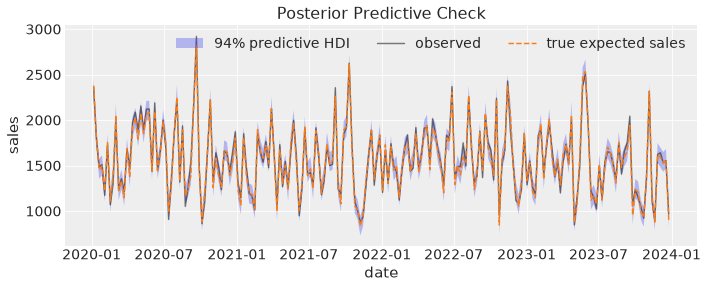

In [8]:
in_sample = gam.sample_posterior_predictive(
    train,
    var_names=[
        "y",
        "sales_response",
        "media_at_reference",
        "market_multiplier",
        "additive_block",
        "baseline",
    ],
    include_last_observations=False,
    random_seed=31,
    progressbar=False,
)
predicted_sales = in_sample["y"] * target_scale
hdi = az.hdi(predicted_sales, prob=0.94)
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.fill_between(
    train["date"],
    hdi.sel(ci_bound="lower"),
    hdi.sel(ci_bound="upper"),
    alpha=0.3,
    label="94% predictive HDI",
)
ax.plot(
    train["date"],
    original["sales"][:n_train],
    color="black",
    alpha=0.5,
    label="observed",
)
ax.plot(
    train["date"],
    true_response[:n_train],
    color="C1",
    linestyle="--",
    label="true expected sales",
)
ax.set(title="Posterior Predictive Check", xlabel="date", ylabel="sales")
ax.legend(ncol=3)
plt.show()

## Media Effects under Market Conditions

For this model, removing channel $c$ changes expected sales by $\beta_c f_c(x_{c,t})M_t$: the multiplier does not depend on spend. We multiply the reference media term by the current multiplier **before** summing over dates. These media removal effects plus the market-scaled baseline reconcile to expected sales per draw and week.

This is not a separate attribution of the multiplier to price and distribution. Those drivers' one-at-a-time removal effects can overlap with media and each other; adding them to this decomposition would double count interactions.

Market-scaled baseline and media reconcile to expected sales per draw and week.


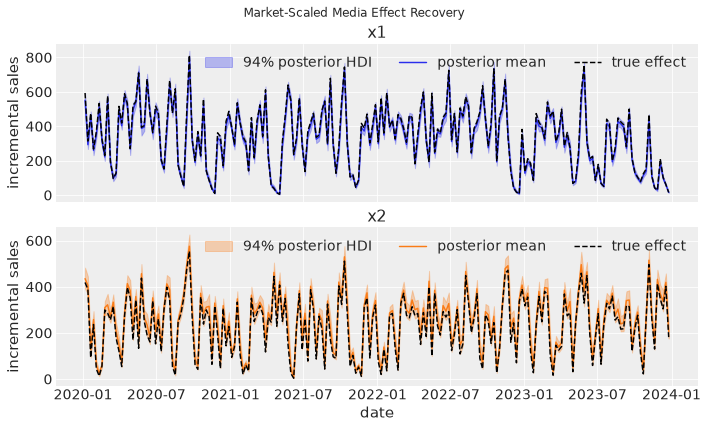

In [9]:
media_contribution = (
    in_sample["media_at_reference"] * in_sample["market_multiplier"] * target_scale
)
scaled_baseline = in_sample["baseline"] * in_sample["market_multiplier"] * target_scale
np.testing.assert_allclose(
    scaled_baseline + media_contribution.sum("channel"),
    in_sample["sales_response"] * target_scale,
    rtol=1e-12,
)
print("Market-scaled baseline and media reconcile to expected sales per draw and week.")

fig, axes = plt.subplots(nrows=2, figsize=(10, 6), sharex=True, layout="constrained")
for i, (channel, ax) in enumerate(zip(channels, axes, strict=True)):
    effect = media_contribution.sel(channel=channel)
    hdi = az.hdi(effect, prob=0.94)
    ax.fill_between(
        train["date"],
        hdi.sel(ci_bound="lower"),
        hdi.sel(ci_bound="upper"),
        color=f"C{i}",
        alpha=0.3,
        label="94% posterior HDI",
    )
    ax.plot(
        train["date"],
        effect.mean(("chain", "draw")),
        color=f"C{i}",
        label="posterior mean",
    )
    ax.plot(
        train["date"],
        true_media_contribution[:n_train, i],
        color="black",
        linestyle="--",
        label="true effect",
    )
    ax.set(title=channel, ylabel="incremental sales")
    ax.legend(ncol=3)
axes[-1].set_xlabel("date")
fig.suptitle("Market-Scaled Media Effect Recovery")
plt.show()

### Neutral References Recover the Additive Model

We can ask the fitted model for the same spend at reference market conditions. This is an in-sample what-if, so again there is no prepended history. Every draw must have a unit market multiplier and a response equal to its additive block.

In [10]:
neutral_inputs = train.drop_vars("sales").assign(
    price=xr.full_like(train["price"], price_reference),
    distribution=xr.full_like(train["distribution"], distribution_reference),
)
neutral = gam.sample_posterior_predictive(
    neutral_inputs,
    var_names=["market_multiplier", "additive_block", "sales_response"],
    include_last_observations=False,
    random_seed=41,
    progressbar=False,
)
np.testing.assert_allclose(neutral["market_multiplier"], 1.0, atol=1e-12)
np.testing.assert_allclose(
    neutral["sales_response"], neutral["additive_block"], rtol=1e-12
)
print(
    "At reference price and distribution, M = 1 and expected sales = A in every draw."
)

Sampling: []


At reference price and distribution, M = 1 and expected sales = A in every draw.


## Forecast and a Price Scenario

The next twelve weeks follow training immediately. Here `include_last_observations=True` carries the last seven training weeks into adstock and drops those history rows from the result. We supply both future market drivers explicitly; the reference constants and posterior parameters stay fixed.

The forecast is conditional on the simulated future spend, price and distribution. A second scenario lowers each future price by 10%, holding spend and distribution fixed. We compare **expected sales**, not independent noisy predictive draws. For the chosen Normal likelihood, `sales_response` is the conditional mean.

In [11]:
forecast = gam.sample_posterior_predictive(
    future,
    var_names=["y", "sales_response"],
    include_last_observations=True,
    random_seed=51,
    progressbar=False,
)
lower_price = gam.sample_posterior_predictive(
    future.assign(price=future["price"] * 0.9),
    var_names=["sales_response"],
    include_last_observations=True,
    random_seed=51,
    progressbar=False,
)
# Check the conditional elasticity identity on paired posterior draws.
np.testing.assert_allclose(
    lower_price["sales_response"] / forecast["sales_response"],
    (0.9 ** posterior["price_elasticity"]).broadcast_like(forecast["sales_response"]),
    rtol=1e-12,
)
forecast_draws = forecast["y"] * target_scale
scenario_gain = (lower_price["sales_response"] - forecast["sales_response"]).sum(
    "date"
) * target_scale
relative_gain = scenario_gain / (forecast["sales_response"].sum("date") * target_scale)
forecast_mean = forecast["sales_response"].mean(("chain", "draw")) * target_scale
forecast_metrics = pd.Series(
    {
        "RMSE against held-out sales": float(
            np.sqrt(((forecast_mean - original["sales"][n_train:]) ** 2).mean())
        ),
        "RMSE against true expected sales": float(
            np.sqrt(((forecast_mean - true_response[n_train:]) ** 2).mean())
        ),
        "mean expected-sales gain (%)": 100 * relative_gain.mean().item(),
        "gain 3% (%)": 100 * np.quantile(relative_gain.values, 0.03),
        "gain 97% (%)": 100 * np.quantile(relative_gain.values, 0.97),
        "P(expected-sales gain > 0)": (scenario_gain > 0).mean().item(),
        "true expected-sales gain (%)": 100 * (0.9**true_price_elasticity - 1),
    },
    name="forecast and price scenario",
)
forecast_metrics.to_frame().round(3)

Sampling: [y]


Sampling: []


,forecast and price scenario
RMSE against held-out sales,60.258
RMSE against true expected sales,12.215
mean expected-sales gain (%),13.420
gain 3% (%),12.992
gain 97% (%),13.847
P(expected-sales gain > 0),1.000
true expected-sales gain (%),13.477


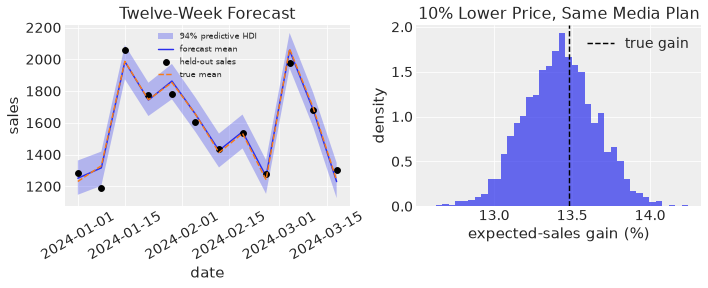

In [12]:
fig, axes = plt.subplots(ncols=2, figsize=(10, 4), layout="constrained")
hdi = az.hdi(forecast_draws, prob=0.94)
axes[0].fill_between(
    future["date"],
    hdi.sel(ci_bound="lower"),
    hdi.sel(ci_bound="upper"),
    alpha=0.3,
    label="94% predictive HDI",
)
axes[0].plot(future["date"], forecast_mean, label="forecast mean")
axes[0].plot(
    future["date"],
    original["sales"][n_train:],
    "o",
    color="black",
    label="held-out sales",
)
axes[0].plot(
    future["date"],
    true_response[n_train:],
    linestyle="--",
    color="C1",
    label="true mean",
)
axes[0].set(title="Twelve-Week Forecast", xlabel="date", ylabel="sales")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8)
axes[1].hist(100 * relative_gain.values.ravel(), bins=40, density=True, alpha=0.7)
axes[1].axvline(
    100 * (0.9**true_price_elasticity - 1),
    color="black",
    linestyle="--",
    label="true gain",
)
axes[1].set(
    title="10% Lower Price, Same Media Plan",
    xlabel="expected-sales gain (%)",
    ylabel="density",
)
axes[1].legend()
plt.show()

The forecast mean has an RMSE of about 12 sales against the true expected response and 60 against the held-out noisy observations, whose generating noise standard deviation is 60. The lower-price scenario gives a mean expected-sales gain of 13.42%, with a 94% equal-tailed interval of 12.99% to 13.85%; the true gain is 13.48%.

The price comparison is a conditional model scenario, not a recommendation to discount: it reports sales, not revenue or profit, and does not include changes in buying behavior beyond the declared elasticity. In real data, causal interpretation would require an identification argument. The paired-draw identity above also checks that the scenario did not accidentally change media history, reference levels or posterior parameters.

## Jointly Optimize Media and Price

The same fitted `sales_response` term can drive a decision over **both** `Data("spend")` and `Data("price")`. Price multiplies the whole additive block, including the baseline, so optimizing only `media_at_reference` would miss part of the price decision.

For this synthetic example, interpret sales as units sold and price as currency per unit. We add an illustrative, known unit cost of 1.60, not a parameter inferred by the model, and maximize posterior expected contribution profit:

$$
\mathbb{E}_{\theta\mid y}\!\left[\sum_t (p_t-c)\,\mu_t(\mathrm{spend},p,\mathrm{distribution};\theta)\right]
-\sum_{t,j}\mathrm{spend}_{t,j}.
$$

This is revenue minus variable production cost and media spend, before fixed costs. Maximizing units instead would favor the lowest allowed price under the recovered negative elasticity; profit makes the price-volume trade-off explicit.

The planning policy is explicit, just as in the additive notebook:

- Plan **8 weeks**, followed by `l_max - 1` weeks with **zero media spend** to score all carryover from the plan.
- Spend the same amount per channel each planned week and choose **one price for all planned weeks**.
- Keep the total media budget equal to business as usual: each channel's historical average weekly spend.
- Bound each channel by its training maximum and price by the observed training range. Fix tail price at 10 and distribution at its 0.8 reference throughout; neither is silently set to zero.
- Start with **no historical carryover**. Business as usual and the optimized plan use exactly the same assumption and scoring window.

The current optimizer requires `inputs` to list every data dependency of the selected term. We therefore declare distribution too, but equal bounds hold it fixed: **only spend and price are movable**. The fitted model uses scaled spend and response, so the callbacks explicitly convert those back to currency and units sold.

In [13]:
plan_weeks = 8
carryover_weeks = l_max - 1
unit_cost = 1.60
scenario_dates = pd.date_range(
    start=train["date"].values[-1],
    periods=1 + plan_weeks + carryover_weeks,
    freq="W-MON",
)[1:]
week = xr.DataArray(
    np.arange(len(scenario_dates)), dims="date", coords={"date": scenario_dates}
)
planned = week < plan_weeks
weekly_spend = train["spend"].mean("date")
budget = float((weekly_spend * channel_scale).sum()) * plan_weeks

business_as_usual = xr.Dataset(
    {
        "spend": weekly_spend.expand_dims(date=scenario_dates)
        .where(planned, 0.0)
        .transpose("date", "channel"),
        "price": xr.full_like(week, price_reference, dtype=float),
        "distribution": xr.full_like(week, distribution_reference, dtype=float),
    }
)
max_spend = (
    xr.ones_like(business_as_usual["spend"]) * train["spend"].max("date")
).where(planned, 0.0)
min_price = xr.where(planned, float(train["price"].min()), price_reference)
max_price = xr.where(planned, float(train["price"].max()), price_reference)

print(f"Media budget for {plan_weeks} planned weeks: {budget:.2f}")
print(
    f"Planned price bounds: {float(train['price'].min()):.2f} "
    f"to {float(train['price'].max()):.2f}; tail price: {price_reference:.2f}"
)
print(f"Fixed distribution: {distribution_reference:.2f}; unit cost: {unit_cost:.2f}")

Media budget for 8 planned weeks: 588.92
Planned price bounds: 8.01 to 11.99; tail price: 10.00
Fixed distribution: 0.80; unit cost: 1.60


`u` contains the symbolic decisions, while `evaluate(u)["sales_response"]` retains the fitted joint posterior draws on a `sample` dimension. We sum profit over all scenario dates, then average over those draws; we do not optimize a separate plan per draw or sample noisy sales inside the solver.

Each equality callback returns a residual that must be zero. The weekly tie masks exclude the first week and the carryover tail, where the residual is identically zero; the tail values are already fixed by bounds.

In [14]:
def expected_profit(evaluate, u):
    """Calculate expected contribution profit in currency over the full scenario."""
    expected_units = evaluate(u)["sales_response"] * target_scale
    margin = ((u["price"] - unit_cost) * expected_units).sum("date")
    media_cost = (
        (u["spend"] * evaluate.constant(channel_scale)).sum("date").sum("channel")
    )
    return margin.mean("sample") - media_cost


def media_budget(evaluate, u):
    """Total media spend in currency minus the fixed budget."""
    spend = u["spend"] * evaluate.constant(channel_scale)
    return spend.sum("date").sum("channel") - budget


def same_weekly_spend(evaluate, u):
    """Tie each planned week's channel spend to the first week's spend."""
    tied = evaluate.constant(planned & (week > 0)) > 0
    return pmd.math.switch(tied, u["spend"] - u["spend"].isel(date=0), 0.0)


def same_weekly_price(evaluate, u):
    """Choose one price for the planned weeks, not for the fixed-price tail."""
    tied = evaluate.constant(planned & (week > 0)) > 0
    return pmd.math.switch(tied, u["price"] - u["price"].isel(date=0), 0.0)


optimized_plan = optimize(
    model=gam,
    terms={"sales_response": sales_response},
    inputs=[spend_data, price_data, distribution_data],
    data=business_as_usual,
    objective=expected_profit,
    bounds={
        "spend": (0.0, max_spend),
        "price": (min_price, max_price),
        "distribution": (distribution_reference, distribution_reference),
    },
    constraints=[
        {"type": "eq", "fun": media_budget},
        {"type": "eq", "fun": same_weekly_spend},
        {"type": "eq", "fun": same_weekly_price},
    ],
    # No history: zero pre-plan media carryover, also used in evaluation below.
    # history=train[["spend", "price", "distribution"]].isel(
    #     date=slice(-carryover_weeks, None)
    # ) would prepend fixed measured history; it would not be optimized.
)

if not (optimized_plan.scipy.success and optimized_plan.feasible):
    raise RuntimeError(f"Optimization failed: {optimized_plan.scipy.message}")

allocation = optimized_plan.allocation
optimized_spend = allocation["spend"] * channel_scale
np.testing.assert_allclose(float(optimized_spend.sum()), budget, atol=1e-6, rtol=1e-8)
for name in ("spend", "price"):
    planned_values = allocation[name].isel(date=slice(0, plan_weeks))
    np.testing.assert_allclose(
        planned_values,
        planned_values.isel(date=0).broadcast_like(planned_values),
        atol=1e-7,
        rtol=1e-8,
    )
np.testing.assert_allclose(allocation["spend"].isel(date=slice(plan_weeks, None)), 0.0)
np.testing.assert_allclose(
    allocation["price"].isel(date=slice(plan_weeks, None)), price_reference
)
np.testing.assert_allclose(allocation["distribution"], distribution_reference)

display(
    pd.Series(
        {
            "SciPy success": optimized_plan.scipy.success,
            "independently feasible": optimized_plan.feasible,
            "budget residual (currency)": float(optimized_plan.constraints[0]),
            "maximum scaled bound violation": optimized_plan.max_bound_violation,
            "maximum scaled constraint violation": optimized_plan.max_constraint_violation,
        },
        name="solver checks",
    ).to_frame()
)
weekly_decisions = pd.DataFrame(
    {
        "business as usual": [
            *(weekly_spend * channel_scale).values,
            price_reference,
        ],
        "optimized": [
            *optimized_spend.isel(date=0).values,
            float(allocation["price"].isel(date=0)),
        ],
    },
    index=[*(f"weekly spend: {channel}" for channel in channels), "price per unit"],
)
weekly_decisions.round(3)

,solver checks
SciPy success,True
independently feasible,True
budget residual (currency),-0.0
maximum scaled bound violation,0.0
maximum scaled constraint violation,0.0


,business as usual,optimized
weekly spend: x1,40.606,47.691
weekly spend: x2,33.009,25.924
price per unit,10.000,9.796


### Evaluate the Joint Plan on Paired Posterior Draws

Business as usual is a plan to evaluate, not an optimization problem with fixed bounds. We use `sample_posterior_predictive` for both plans, selecting the expected response rather than noisy observations. This independent evaluation must reproduce the optimizer's reported objective.

Both evaluations reuse the same fitted posterior draws, no training carryover, fixed distribution and tail policy. Their draw-by-draw difference measures uncertainty in the expected profit improvement under these assumptions, not uncertainty in realized sales or in the supplied unit cost.

In [15]:
def evaluate_plan(plan):
    """Evaluate total units, revenue and contribution profit for each fitted draw."""
    prediction = gam.sample_posterior_predictive(
        plan,
        var_names=["sales_response"],
        include_last_observations=False,
        random_seed=71,
        progressbar=False,
    )
    units = prediction["sales_response"] * target_scale
    media_cost = (plan["spend"] * channel_scale).sum()
    return xr.Dataset(
        {
            "units": units.sum("date"),
            "revenue": (plan["price"] * units).sum("date"),
            "contribution profit": ((plan["price"] - unit_cost) * units).sum("date")
            - media_cost,
        }
    )


bau_outcomes = evaluate_plan(business_as_usual)
optimized_outcomes = evaluate_plan(allocation)
np.testing.assert_allclose(
    float(optimized_outcomes["contribution profit"].mean()),
    optimized_plan.objective,
    rtol=1e-10,
)
print("Posterior-predictive evaluation reproduces the optimizer objective.")
comparison = pd.DataFrame(
    {
        label: {
            "expected units": float(outcomes["units"].mean()),
            "expected revenue": float(outcomes["revenue"].mean()),
            "expected contribution profit": float(
                outcomes["contribution profit"].mean()
            ),
        }
        for label, outcomes in (
            ("business as usual", bau_outcomes),
            ("optimized", optimized_outcomes),
        )
    }
)
display(comparison.round(2))

profit_gain = (
    optimized_outcomes["contribution profit"] - bau_outcomes["contribution profit"]
)
profit_gain_summary = pd.Series(
    {
        "mean expected-profit gain (currency)": float(profit_gain.mean()),
        "gain as % of BAU expected profit": 100
        * float(profit_gain.mean() / bau_outcomes["contribution profit"].mean()),
        "gain: 3% quantile (currency)": float(profit_gain.quantile(0.03)),
        "gain: 97% quantile (currency)": float(profit_gain.quantile(0.97)),
        "posterior P(expected-profit gain > 0)": float((profit_gain > 0).mean()),
    },
    name="paired posterior comparison",
)
display(profit_gain_summary.round(3).to_frame())

# With the known generating elasticity, the price-only optimum has this closed form.
# This is a sanity check, not an input to optimization.
true_optimal_price = true_price_elasticity * unit_cost / (true_price_elasticity + 1.0)
print(f"Known-DGP optimal planned price, for comparison: {true_optimal_price:.2f}")

Sampling: []


Sampling: []


Posterior-predictive evaluation reproduces the optimizer objective.


,business as usual,optimized
expected units,20306.63,20689.06
expected revenue,203066.34,204179.72
expected contribution profit,169986.80,170488.31


,paired posterior comparison
mean expected-profit gain (currency),501.512
gain as % of BAU expected profit,0.295
gain: 3% quantile (currency),89.736
gain: 97% quantile (currency),903.537
posterior P(expected-profit gain > 0),0.986


Known-DGP optimal planned price, for comparison: 9.60


Both decisions move: spend shifts toward $x_1$ while retaining $x_2$, and the selected price is below business as usual but above its lower bound. The objective trades off demand against margin rather than simply minimizing price. The paired comparison reports uncertainty in expected profit, and does not imply that every posterior draw or future realization benefits.

This is a local, posterior-expected-profit solution under the declared constraints, not a global optimum certificate or a real-world pricing recommendation. The synthetic price and media inputs were independently varied; observational applications need an identification argument, defensible price response, externally justified costs and constraints, and a policy for distribution and carryover.

## What Changed from the Additive Notebook?

The media pipeline, labeled inputs and `Equation` workflow are the same. The model definition now separates a positive additive block from a dimensionless multiplier and explicitly multiplies them. Reference conditions and the Normal noise model are visible in the specification rather than implicit in a model-wide link choice.

The diagnostic and recovery tables above show the results of this run. The numerical checks establish that the graph matches the generating equation, the multiplier is neutral at its references, media effects reconcile under the stated decomposition, and the forecast price scenario respects its elasticity in every posterior draw. These checks do not remove sampling uncertainty or establish identification for observational data.

The optimization selects the full response, not the unmultiplied `media_at_reference`, and makes both the media allocation and the price explicit decisions. Fixed distribution, the carryover tail, the spend budget and the profit objective are caller-authored policies, not special cases inside the model. General reconciled attribution across additive and multiplicative drivers remains a separate reporting choice; it is not inferred from the names of the terms.

In [16]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor,nutpie

Last updated: Wed, 14 Oct 2026

Python implementation: CPython
Python version       : 3.13.9
IPython version      : 9.15.0

pymc_marketing: 1.1.0
pytensor      : 3.3.2
nutpie        : 0.16.11

IPython       : 9.15.0
arviz         : 1.2.0
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.1.0
pytensor      : 3.3.2
xarray        : 2026.4.0

Watermark: 2.6.0

